# Lab 7: Healthcare Operations and Resource Optimization

**AI in Healthcare · Unit II · Completed lab · Approximately 120 minutes**  
**Companion lecture:** [Healthcare Operations and Resource Optimization](../lectures/session-07-healthcare-operations-resource-optimization.ipynb)

## Learning objectives

By the end of this lab, you should be able to:

1. Audit synthetic appointment requests and distinguish predictions from realized outcomes.
2. Trace a multi-clinician outpatient queue.
3. Calculate access, waiting, utilization, overtime, and urgent-delay measures.
4. Compare booking policies across repeated uncertain clinic days.
5. Test sensitivity to changing demand and model miscalibration.
6. Recommend a policy while stating safety, equity, and deployment limitations.

**Prerequisites:** Python, pandas, NumPy, descriptive statistics, and the companion lecture.  
**Dependencies:** Python 3, NumPy, pandas, and matplotlib. No downloads or installation cells are required.

All patient identifiers, probabilities, groups, events, and results in this notebook are deterministic synthetic teaching fixtures. The lab does not provide clinical advice or evidence that a policy is suitable for a real clinic.

## Scenario and decision frame

You support a fictional outpatient clinic with two clinicians and an eight-hour day. The normal template contains 30 appointment places. The manager is considering:

- retaining the baseline template;
- reserving places for uncertain same-day urgent demand;
- adding limited bookings to slots whose scheduled patient has a high predicted non-attendance probability; or
- using non-preemptive urgency priority when selecting the next waiting patient.

The schedule must be created **before the clinic opens**. Predicted non-attendance probability is available then. Actual attendance, arrival delay, consultation duration, and urgent requests are future realizations and must not be used to construct the schedule.

| Item | Definition |
|---|---|
| Intended user | Clinic manager |
| Unit in `requests` | One appointment request |
| Unit in a simulated queue | One attended visit or urgent request |
| Decision time | Before clinic opening |
| Action | Choose reservation, overbooking, and queue rules |
| Main outcomes | Access, waiting, overtime, utilization, urgent delay, subgroup effects |

The clinic and its 30-minute urgent-wait review threshold are illustrative, not clinical standards.

## Deliverables and rubric

Submit the completed notebook with:

1. data audit and interpretation;
2. validated baseline queue trace;
3. policy-comparison table over repeated days;
4. at least two plots showing both typical and high-delay outcomes;
5. demand and calibration sensitivity results;
6. subgroup audit with sample sizes; and
7. a concise recommendation memo with assumptions and limitations.

| Criterion | Marks |
|---|---:|
| Data audit, row meaning, and decision-time reasoning | 15 |
| Queue trace and operational metrics | 20 |
| Reproducible repeated-policy comparison | 25 |
| Uncertainty and sensitivity analysis | 15 |
| Safety and subgroup evaluation | 15 |
| Interpretation, recommendation, and limitations | 10 |
| **Total** | **100** |

Code that runs is necessary but not sufficient. Marks depend on explaining what the outputs mean and what the simulation cannot establish.

## Setup and generate the fixture — 10 minutes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

CLINIC_CLOSE_MINUTE = 480  # 17:00 when minute 0 represents 09:00
BASE_TEMPLATE_SIZE = 30
N_CLINICIANS = 2
URGENT_WAIT_REVIEW_MIN = 30  # illustrative lab rule, not a clinical standard

In [2]:
def make_synthetic_requests(seed=7, n_requests=40):
    # Create fictional requests and scores available before the clinic day.
    rng = np.random.default_rng(seed)
    access_group = rng.choice(
        ["near_clinic", "far_from_clinic"],
        size=n_requests,
        p=[0.65, 0.35],
    )
    travel_minutes = np.where(
        access_group == "near_clinic",
        rng.integers(5, 31, n_requests),
        rng.integers(35, 91, n_requests),
    )
    prior_missed = rng.binomial(2, np.where(access_group == "near_clinic", 0.12, 0.22))
    raw_score = -2.8 + 0.018 * travel_minutes + 0.75 * prior_missed
    predicted_no_show = 1 / (1 + np.exp(-raw_score))

    requests = pd.DataFrame(
        {
            "request_id": [f"R{i:03d}" for i in range(n_requests)],
            "patient_id": [f"P{i:03d}" for i in range(n_requests)],
            "request_order": np.arange(1, n_requests + 1),
            "access_group": access_group,
            "travel_minutes": travel_minutes,
            "prior_missed_appointments": prior_missed,
            "predicted_no_show_probability": np.clip(predicted_no_show, 0.05, 0.60),
        }
    )
    return requests


requests = make_synthetic_requests()
requests.head()

,request_id,patient_id,request_order,access_group,travel_minutes,prior_missed_appointments,predicted_no_show_probability
0,R000,P000,1,near_clinic,18,0,0.077558
1,R001,P001,2,far_from_clinic,68,1,0.304492
2,R002,P002,3,far_from_clinic,59,0,0.149567
3,R003,P003,4,near_clinic,27,0,0.089970
4,R004,P004,5,near_clinic,9,1,0.131473


The fixture is **hand-created synthetic data**, not an export from a clinical system. `access_group` exists to investigate whether a policy produces different outcomes; it is not a clinical urgency label.

The no-show score is generated partly from travel time and prior missed appointments. This deliberately creates an ethical issue: a scheduling rule may convert an access barrier into worse service for the people affected by it.

## Exercise 1: Audit appointment requests — 10 minutes

1. Confirm the row count and uniqueness of `request_id` and `patient_id`.
2. Check ranges and missingness.
3. Summarize request count and predicted non-attendance probability by `access_group`.
4. State whether `predicted_no_show_probability` is a prediction, decision, or observed outcome.
5. Explain why the eventual `showed_up` value must not appear in this table.

Complete the cell below. Preserve one row per appointment request.

In [3]:
print("Rows:", len(requests))
print("Unique request_id:", requests["request_id"].nunique(), "| Unique patient_id:", requests["patient_id"].nunique())
display(requests.isna().sum().rename("missing").to_frame())
display(requests.describe().round(3))

request_audit_by_group = requests.groupby("access_group").agg(
    requests=("request_id", "count"),
    mean_travel_min=("travel_minutes", "mean"),
    mean_no_show=("predicted_no_show_probability", "mean"),
    min_no_show=("predicted_no_show_probability", "min"),
    max_no_show=("predicted_no_show_probability", "max"),
).round(3)
request_audit_by_group

Rows: 40
Unique request_id: 40 | Unique patient_id: 40


,missing
request_id,0
patient_id,0
request_order,0
access_group,0
travel_minutes,0
prior_missed_appointments,0
predicted_no_show_probability,0


,request_order,travel_minutes,prior_missed_appointments,predicted_no_show_probability
count,40.00,40.000,40.000,40.000
mean,20.50,29.625,0.275,0.125
std,11.69,22.575,0.452,0.068
min,1.00,6.000,0.000,0.063
25%,10.75,14.000,0.000,0.077
50%,20.50,20.500,0.000,0.094
75%,30.25,44.000,1.000,0.154
max,40.00,89.000,1.000,0.320


,requests,mean_travel_min,mean_no_show,min_no_show,max_no_show
access_group,,,,,
far_from_clinic,11,62.818,0.198,0.117,0.320
near_clinic,29,17.034,0.097,0.063,0.171


In [4]:
assert requests["request_id"].is_unique, "request_id must be unique"
assert requests["patient_id"].is_unique, "This fixture expects one request per patient"
assert requests["predicted_no_show_probability"].between(0, 1).all()

if request_audit_by_group is None:
    print("Complete Exercise 1: create request_audit_by_group.")
else:
    display(request_audit_by_group)

,requests,mean_travel_min,mean_no_show,min_no_show,max_no_show
access_group,,,,,
far_from_clinic,11,62.818,0.198,0.117,0.320
near_clinic,29,17.034,0.097,0.063,0.171


The 40 rows represent individual requests from 40 distinct patients and all fields are complete. Travel ranges from 6 to 89 minutes and prior misses from 0 to 1. The 11 far-group requests average a predicted no-show probability of 19.8%, compared with 9.7% across 29 near-group requests. Travel contributes to the score, so a booking rule could turn an access barrier into more crowded slots. The probability is a pre-opening prediction. The booking and queue rule are decisions. Actual attendance is an outcome observed on the clinic day. Including the showed_up field in scheduling inputs would leak future information.

## Build schedules and simulate the queue

The following functions are provided infrastructure. Read their docstrings before using them.

`build_schedule` creates a decision using only pre-opening information. Reserving a place reduces routine bookings. Score-guided overbooking assigns additional requests to times associated with the highest predicted non-attendance probabilities; it does not deny the original patient an appointment.

In [5]:
def build_schedule(
    request_table,
    reserve_slots=0,
    overbook_slots=0,
    score_guided_overbooking=False,
    base_template_size=BASE_TEMPLATE_SIZE,
):
    # Create a pre-opening schedule without using realized attendance.
    if reserve_slots < 0 or overbook_slots < 0:
        raise ValueError("reserve_slots and overbook_slots must be non-negative")
    regular_places = base_template_size - reserve_slots
    if regular_places <= 0:
        raise ValueError("reserve_slots leave no routine appointment places")
    if regular_places + overbook_slots > len(request_table):
        raise ValueError("Not enough appointment requests for this policy")

    template = np.repeat(np.arange(0, 450, 30), 2)
    if reserve_slots:
        # Spread nominal reserved capacity across the day instead of simply
        # removing the final appointments. Same-day arrivals still join the queue.
        reserved_positions = np.floor(
            (np.arange(reserve_slots) + 0.5) * len(template) / reserve_slots
        ).astype(int)
        regular_template = np.delete(template, reserved_positions)
    else:
        regular_template = template
    selected = request_table.sort_values("request_order").head(regular_places).copy()
    selected["scheduled_minute"] = regular_template[:regular_places]
    selected["booking_type"] = "standard"

    if overbook_slots:
        waitlist = (
            request_table.sort_values("request_order")
            .iloc[regular_places : regular_places + overbook_slots]
            .copy()
        )
        if score_guided_overbooking:
            host_slots = selected.nlargest(
                overbook_slots, "predicted_no_show_probability"
            )["scheduled_minute"].to_numpy()
        else:
            host_slots = selected.tail(overbook_slots)["scheduled_minute"].to_numpy()
        waitlist["scheduled_minute"] = host_slots
        waitlist["booking_type"] = "overbooked"
        selected = pd.concat([selected, waitlist], ignore_index=True)

    return selected.sort_values(
        ["scheduled_minute", "booking_type", "request_order"], kind="stable"
    ).reset_index(drop=True)


baseline_schedule = build_schedule(requests)
baseline_schedule[[
    "request_id",
    "patient_id",
    "scheduled_minute",
    "booking_type",
    "predicted_no_show_probability",
]].head(8)

,request_id,patient_id,scheduled_minute,booking_type,predicted_no_show_probability
0,R000,P000,0,standard,0.077558
1,R001,P001,0,standard,0.304492
2,R002,P002,30,standard,0.149567
3,R003,P003,30,standard,0.089970
4,R004,P004,60,standard,0.131473
5,R005,P005,60,standard,0.319950
6,R006,P006,90,standard,0.092961
7,R007,P007,90,standard,0.116500


In [6]:
def process_queue(arrivals, n_clinicians=N_CLINICIANS, queue_rule="fcfs"):
    # Run a non-preemptive multi-clinician queue. FCFS selects the
    # longest-waiting arrival; urgent_priority selects urgent visits first,
    # then by arrival. A consultation in progress is never interrupted.
    if queue_rule not in {"fcfs", "urgent_priority"}:
        raise ValueError("queue_rule must be 'fcfs' or 'urgent_priority'")
    if n_clinicians < 1:
        raise ValueError("n_clinicians must be at least 1")

    pending = arrivals.sort_values("arrival_minute", kind="stable").reset_index(drop=True)
    server_available = np.zeros(n_clinicians, dtype=float)
    waiting = []
    records = []
    next_arrival_index = 0
    current_time = 0.0

    while next_arrival_index < len(pending) or waiting:
        if not waiting:
            current_time = max(
                current_time,
                float(pending.loc[next_arrival_index, "arrival_minute"]),
            )

        while (
            next_arrival_index < len(pending)
            and pending.loc[next_arrival_index, "arrival_minute"] <= current_time
        ):
            waiting.append(pending.loc[next_arrival_index].to_dict())
            next_arrival_index += 1

        free_servers = np.flatnonzero(server_available <= current_time)
        while waiting and len(free_servers):
            if queue_rule == "urgent_priority":
                chosen_index = min(
                    range(len(waiting)),
                    key=lambda i: (
                        0 if waiting[i]["urgency"] == "urgent" else 1,
                        waiting[i]["arrival_minute"],
                        waiting[i]["visit_id"],
                    ),
                )
            else:
                chosen_index = min(
                    range(len(waiting)),
                    key=lambda i: (waiting[i]["arrival_minute"], waiting[i]["visit_id"]),
                )

            visit = waiting.pop(chosen_index)
            server = int(free_servers[0])
            start = current_time
            finish = start + float(visit["service_duration_min"])
            records.append(
                {
                    **visit,
                    "clinician": server + 1,
                    "service_start_minute": start,
                    "completion_minute": finish,
                    "wait_min": start - float(visit["arrival_minute"]),
                }
            )
            server_available[server] = finish
            free_servers = np.flatnonzero(server_available <= current_time)

        if waiting:
            current_time = float(server_available.min())
        elif next_arrival_index < len(pending):
            current_time = max(
                current_time,
                float(pending.loc[next_arrival_index, "arrival_minute"]),
            )

    if not records:
        return pending.assign(
            clinician=pd.Series(dtype=int),
            service_start_minute=pd.Series(dtype=float),
            completion_minute=pd.Series(dtype=float),
            wait_min=pd.Series(dtype=float),
        )
    return pd.DataFrame(records).sort_values(
        ["service_start_minute", "clinician"], kind="stable"
    ).reset_index(drop=True)


def simulate_clinic_day(
    schedule,
    seed,
    n_clinicians=N_CLINICIANS,
    queue_rule="fcfs",
    urgent_rate=4.0,
    no_show_logit_shift=0.0,
):
    # Realize attendance and demand, then process one fictional clinic day.
    # no_show_logit_shift changes actual non-attendance odds while leaving the
    # pre-opening predicted probabilities unchanged. It supports a drift test.
    # Independent streams keep urgent demand and shared patient outcomes aligned
    # when the same seed is used to compare policies of different sizes.
    streams = np.random.SeedSequence(seed).spawn(6)
    attendance_rng, arrival_rng, service_rng, urgent_count_rng, urgent_arrival_rng, urgent_service_rng = [
        np.random.default_rng(stream) for stream in streams
    ]
    regular = schedule.copy()
    predicted = regular["predicted_no_show_probability"].to_numpy()
    predicted_logit = np.log(predicted / (1 - predicted))
    actual_no_show_probability = 1 / (
        1 + np.exp(-(predicted_logit + no_show_logit_shift))
    )
    # Keep each request's draws fixed when policies reorder or remove bookings.
    request_index = regular["request_order"].to_numpy(dtype=int) - 1
    draw_count = int(request_index.max()) + 1 if len(request_index) else 0
    showed_up = attendance_rng.random(draw_count)[request_index] >= actual_no_show_probability
    arrival_offsets = arrival_rng.normal(0, 8, draw_count)[request_index][showed_up]
    durations = service_rng.lognormal(np.log(24), 0.35, draw_count)[request_index][showed_up]

    attended = regular.loc[showed_up].copy()
    attended["visit_id"] = "V-" + attended["request_id"]
    attended["source"] = "scheduled"
    attended["urgency"] = "routine"
    attended["arrival_minute"] = np.maximum(
        0,
        attended["scheduled_minute"].to_numpy()
        + arrival_offsets,
    )
    attended["service_duration_min"] = np.clip(
        durations, 8, 60
    )

    urgent_count = urgent_count_rng.poisson(urgent_rate)
    urgent = pd.DataFrame(
        {
            "visit_id": [f"U-{seed}-{i}" for i in range(urgent_count)],
            "request_id": pd.NA,
            "patient_id": [f"UP-{seed}-{i}" for i in range(urgent_count)],
            "request_order": pd.NA,
            "access_group": "not_recorded_for_urgent_fixture",
            "travel_minutes": np.nan,
            "prior_missed_appointments": np.nan,
            "predicted_no_show_probability": np.nan,
            "scheduled_minute": np.nan,
            "booking_type": "same_day_request",
            "source": "same_day",
            "urgency": "urgent",
            "arrival_minute": urgent_arrival_rng.uniform(0, 420, urgent_count),
            "service_duration_min": np.clip(
                urgent_service_rng.lognormal(np.log(30), 0.35, urgent_count), 10, 75
            ),
        }
    )

    arrivals = pd.concat([attended, urgent], ignore_index=True, sort=False)
    return process_queue(arrivals, n_clinicians=n_clinicians, queue_rule=queue_rule)

### Validate the queue engine

Before trusting a complex simulation, test a deterministic case whose answer can be calculated by hand. The assertions below expect waits of 0, 15, and 10 minutes for one clinician.

In [7]:
toy_arrivals = pd.DataFrame(
    {
        "visit_id": ["P1", "P2", "P3"],
        "patient_id": ["P1", "P2", "P3"],
        "source": ["scheduled"] * 3,
        "urgency": ["routine"] * 3,
        "access_group": ["toy"] * 3,
        "arrival_minute": [0.0, 5.0, 25.0],
        "service_duration_min": [20.0, 15.0, 10.0],
    }
)
toy_result = process_queue(toy_arrivals, n_clinicians=1, queue_rule="fcfs")

assert toy_result["wait_min"].tolist() == [0.0, 15.0, 10.0]
assert toy_result["completion_minute"].tolist() == [20.0, 35.0, 45.0]
print("Deterministic FCFS check passed.")
toy_result[[
    "visit_id", "arrival_minute", "service_start_minute",
    "completion_minute", "wait_min"
]]

Deterministic FCFS check passed.


,visit_id,arrival_minute,service_start_minute,completion_minute,wait_min
0,P1,0.0,0.0,20.0,0.0
1,P2,5.0,20.0,35.0,15.0
2,P3,25.0,35.0,45.0,10.0


In the one-clinician check, P1 starts at minute 0 and finishes at 20. P2 arrives at 5, starts at 20 and finishes at 35. P3 arrives at 25, starts at 35 and finishes at 45. The respective waits are 0, 15 and 10 minutes.

## Exercise 2: Trace one baseline clinic day — 15 minutes

1. Simulate seed `2026` using `baseline_schedule` and FCFS.
2. Check that waits and service durations are non-negative.
3. Display the five longest waits.
4. Explain why `len(day)` is the number of attended/same-day visits, not the number of scheduled appointments or unique requests.
5. Plot a clinician timeline using horizontal bars. Use different colours for routine and urgent visits.

Visit mix: {'scheduled': 28, 'same_day': 4}
Visits in this day: 32 | Scheduled appointments: 30


,visit_id,urgency,clinician,arrival_minute,service_start_minute,wait_min
10,V-R011,routine,2,131.9,163.1,31.2
2,V-R002,routine,1,21.3,43.6,22.2
11,V-R010,routine,1,149.2,167.0,17.8
19,V-R018,routine,1,269.4,284.8,15.4
7,V-R007,routine,1,95.1,108.9,13.8


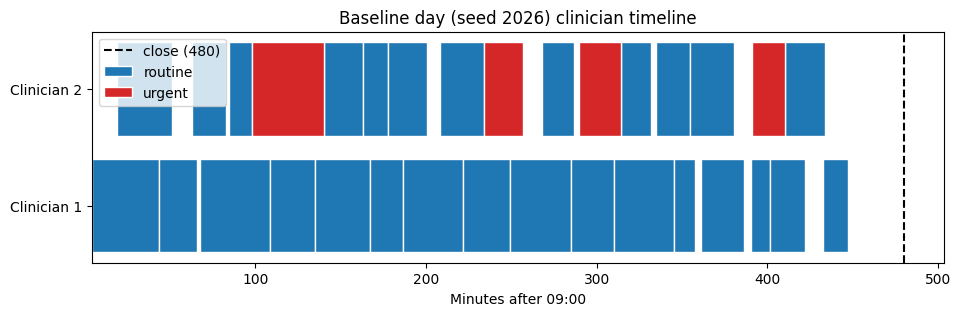

In [8]:
baseline_day = simulate_clinic_day(
    baseline_schedule,
    seed=2026,
    n_clinicians=N_CLINICIANS,
    queue_rule="fcfs",
)

assert (baseline_day["wait_min"] >= 0).all()
assert (baseline_day["service_duration_min"] > 0).all()
assert (baseline_day["completion_minute"] >= baseline_day["service_start_minute"]).all()
assert (baseline_day["service_start_minute"] >= baseline_day["arrival_minute"]).all()
for _, clinician_visits in baseline_day.groupby("clinician"):
    assert (clinician_visits["service_start_minute"].iloc[1:].to_numpy()
            >= clinician_visits["completion_minute"].iloc[:-1].to_numpy()).all()
print("Visit mix:", baseline_day["source"].value_counts().to_dict())
print("Visits in this day:", len(baseline_day), "| Scheduled appointments:", len(baseline_schedule))

# Five longest waits
display(baseline_day.nlargest(5, "wait_min")[
    ["visit_id", "urgency", "clinician", "arrival_minute", "service_start_minute", "wait_min"]
].round(1))

# Clinician timeline
fig, ax = plt.subplots(figsize=(11, 3))
for urgency, color in [("routine", "tab:blue"), ("urgent", "tab:red")]:
    d = baseline_day[baseline_day["urgency"] == urgency]
    ax.barh(d["clinician"], d["service_duration_min"], left=d["service_start_minute"],
            color=color, edgecolor="white", label=urgency)
ax.axvline(CLINIC_CLOSE_MINUTE, color="black", ls="--", label="close (480)")
ax.set(yticks=[1, 2], yticklabels=["Clinician 1", "Clinician 2"],
       xlabel="Minutes after 09:00", title="Baseline day (seed 2026) clinician timeline")
ax.legend(loc="upper left")
plt.show()

Each trace row is an attended scheduled visit or a same-day urgent arrival. The row count excludes no-shows and unbooked requests. The timeline shows overlapping work across clinicians, and the assertions verify that each clinician handles only one visit at a time. Seed 2026 produces 32 visits from 28 attended appointments and four same-day urgent arrivals. All 32 start before close. The median wait is 3.56 minutes and the longest wait is 31.20 minutes for routine visit V-R011. Neither clinician works past close, and no urgent visit crosses the review threshold.

## Exercise 3: Calculate operational outcomes — 20 minutes

Implement `summarise_day`. Return a dictionary containing at least:

- `visits`
- `started_by_close`
- `mean_wait_min`
- `median_wait_min`
- `p90_wait_min`
- `max_wait_min`
- `utilization_before_close`
- `overtime_min`
- `urgent_visits`
- `urgent_wait_breaches`

For utilization, count only the part of each consultation falling between minute 0 and minute 480:

$$
\text{busy before close}=
\sum_i \max(0,\min(f_i,480)-\max(s_i,0)),
$$

then divide by `n_clinicians × 480`. Here $s_i$ and $f_i$ are visit $i$'s service start and finish.

In [9]:
def summarise_day(
    visits,
    n_clinicians=N_CLINICIANS,
    closing_minute=CLINIC_CLOSE_MINUTE,
    urgent_wait_review_min=URGENT_WAIT_REVIEW_MIN,
):
    start, finish, wait = visits["service_start_minute"], visits["completion_minute"], visits["wait_min"]
    busy = (np.minimum(finish, closing_minute) - np.maximum(start, 0)).clip(lower=0).sum()
    urgent = visits[visits["urgency"] == "urgent"]
    return {
        "visits": len(visits),
        "started_by_close": int((start < closing_minute).sum()),
        "mean_wait_min": wait.mean(),
        "median_wait_min": wait.median(),
        "p90_wait_min": wait.quantile(0.90),
        "max_wait_min": wait.max(),
        "utilization_before_close": busy / (n_clinicians * closing_minute),
        "overtime_min": max(0.0, finish.max() - closing_minute) if len(visits) else 0.0,
        "routine_p90_wait_min": wait[visits["urgency"].eq("routine")].quantile(0.90),
        "urgent_visits": len(urgent),
        "urgent_wait_breaches": int((urgent["wait_min"] > urgent_wait_review_min).sum()),
    }


baseline_metrics = summarise_day(baseline_day)
display(pd.Series(baseline_metrics, name="baseline_seed_2026").round(2))

visits                      32.00
started_by_close            32.00
mean_wait_min                5.89
median_wait_min              3.56
p90_wait_min                15.26
max_wait_min                31.20
utilization_before_close     0.82
overtime_min                 0.00
routine_p90_wait_min        16.14
urgent_visits                4.00
urgent_wait_breaches         0.00
Name: baseline_seed_2026, dtype: float64

### Metric checks

Use checks as debugging aids, not as substitutes for interpretation. The utilization definition above should remain between 0 and 1 because it counts only busy time inside the staffed window. Overtime is reported separately.

In [10]:
required_metrics = {
    "visits", "started_by_close", "mean_wait_min", "median_wait_min",
    "p90_wait_min", "max_wait_min", "utilization_before_close",
    "overtime_min", "urgent_visits", "urgent_wait_breaches",
}
assert required_metrics.issubset(baseline_metrics)
assert 0 <= baseline_metrics["utilization_before_close"] <= 1
assert baseline_metrics["mean_wait_min"] <= baseline_metrics["max_wait_min"]
assert baseline_metrics["urgent_wait_breaches"] <= baseline_metrics["urgent_visits"]
print("Metric checks passed.")

Metric checks passed.


Utilization measures the share of the two clinicians' combined 960 staffed minutes spent with patients before closing. Overtime is elapsed time from closing until the final completion. A visit counts as started by close when service starts strictly before minute 480. The urgent breach threshold is strictly greater than 30 minutes. Wait summaries are undefined on empty days.

## Exercise 4: Compare scheduling policies — 25 minutes

The candidate policies below change one or more decisions:

- **Baseline:** 30 standard bookings, FCFS.
- **Reserve two:** 28 standard bookings, leaving nominal capacity for same-day demand.
- **Score-guided overbook two:** 30 standard plus two additional requests assigned to high predicted no-show slots.
- **Urgent priority:** baseline bookings with non-preemptive priority for urgent arrivals.

First inspect schedule counts and duplicate slot times. Then run every policy for at least 200 days. Use the same simulation seeds for each policy so that comparisons are not driven merely by different random-number sequences.

In [11]:
policy_definitions = {
    "baseline_fcfs": {
        "schedule": build_schedule(requests),
        "queue_rule": "fcfs",
    },
    "reserve_2_fcfs": {
        "schedule": build_schedule(requests, reserve_slots=2),
        "queue_rule": "fcfs",
    },
    "overbook_2_score_guided": {
        "schedule": build_schedule(
            requests,
            overbook_slots=2,
            score_guided_overbooking=True,
        ),
        "queue_rule": "fcfs",
    },
    "baseline_urgent_priority": {
        "schedule": build_schedule(requests),
        "queue_rule": "urgent_priority",
    },
}

pd.DataFrame(
    [
        {
            "policy": name,
            "scheduled_requests": len(spec["schedule"]),
            "overbooked_requests": (spec["schedule"]["booking_type"] == "overbooked").sum(),
            "shared_slot_times": int(spec["schedule"]["scheduled_minute"].value_counts().gt(1).sum()),
            "slot_times_with_extra_load": int(spec["schedule"]["scheduled_minute"].value_counts().gt(2).sum()),
            "queue_rule": spec["queue_rule"],
        }
        for name, spec in policy_definitions.items()
    ]
)

,policy,scheduled_requests,overbooked_requests,shared_slot_times,slot_times_with_extra_load,queue_rule
0,baseline_fcfs,30,0,15,0,fcfs
1,reserve_2_fcfs,28,0,13,0,fcfs
2,overbook_2_score_guided,32,2,15,2,fcfs
3,baseline_urgent_priority,30,0,15,0,urgent_priority


The normal template puts two appointments at each nominal slot. The extra-load column isolates slots with more than two bookings. Reservation frees two routine template places and urgent arrivals still join the queue when they arrive. Each request keeps its own attendance, arrival and duration draws across policies, and the same 300 day seeds and urgent streams are reused.

In [12]:
def evaluate_policy(
    policy_name,
    policy_spec,
    seeds,
    urgent_rate=4.0,
    no_show_logit_shift=0.0,
):
    # Reuse the same days and request-level draws for every policy.
    rows = []
    for simulation_id, seed in enumerate(seeds):
        visits = simulate_clinic_day(
            policy_spec["schedule"],
            seed=int(seed),
            n_clinicians=N_CLINICIANS,
            queue_rule=policy_spec["queue_rule"],
            urgent_rate=urgent_rate,
            no_show_logit_shift=no_show_logit_shift,
        )
        metrics = summarise_day(visits)
        rows.append(
            {
                "policy": policy_name,
                "simulation_id": simulation_id,
                "seed": int(seed),
                **metrics,
            }
        )
    return pd.DataFrame(rows)


simulation_seeds = np.arange(20_000, 20_300)

def run_all_policies(**kwargs):
    # Same seeds for every policy -> fair comparison
    return pd.concat(
        [evaluate_policy(name, spec, simulation_seeds, **kwargs) for name, spec in policy_definitions.items()],
        ignore_index=True,
    )


policy_results = run_all_policies()

assert policy_results.groupby("policy")["seed"].nunique().eq(len(simulation_seeds)).all()
assert policy_results.groupby("seed")["urgent_visits"].nunique().eq(1).all()
display(policy_results.head())

,policy,simulation_id,seed,visits,started_by_close,mean_wait_min,median_wait_min,p90_wait_min,max_wait_min,utilization_before_close,overtime_min,routine_p90_wait_min,urgent_visits,urgent_wait_breaches
0,baseline_fcfs,0,20000,29,29,20.185363,18.741289,48.304270,69.688217,0.861583,9.396137,50.450127,4,1
1,baseline_fcfs,1,20001,32,32,27.540284,31.177098,46.322062,64.209631,0.923842,0.000000,45.053072,5,2
2,baseline_fcfs,2,20002,34,31,54.782399,59.588405,88.415812,97.503507,0.923599,73.329528,86.831017,6,4
3,baseline_fcfs,3,20003,34,34,35.785751,41.044166,63.080693,79.723877,0.959278,28.952819,63.792612,7,2
4,baseline_fcfs,4,20004,30,30,5.089009,0.451614,14.326340,30.184471,0.790778,0.000000,14.347189,2,0


Create a policy summary with:

- median visits and started-by-close count;
- median mean wait;
- median and 90th percentile of daily `p90_wait_min`;
- median utilization;
- 90th-percentile overtime; and
- mean urgent-wait breaches.

Then plot at least `mean_wait_min` and `overtime_min` distributions by policy. Explain why reporting only the mean across all simulations would be insufficient.

,median_visits,median_started_by_close,median_mean_wait,median_p90_wait,p90_of_p90_wait,median_utilization,p90_overtime,mean_urgent_breaches,median_routine_p90_wait
policy,,,,,,,,,
baseline_fcfs,30.0,30.0,9.37,25.25,54.73,0.82,19.76,0.81,24.83
baseline_urgent_priority,30.0,30.0,9.61,26.45,59.07,0.82,21.33,0.04,26.84
overbook_2_score_guided,32.0,32.0,12.42,30.13,60.18,0.87,35.65,1.00,29.09
reserve_2_fcfs,28.0,28.0,7.54,20.62,47.23,0.77,7.86,0.56,20.69


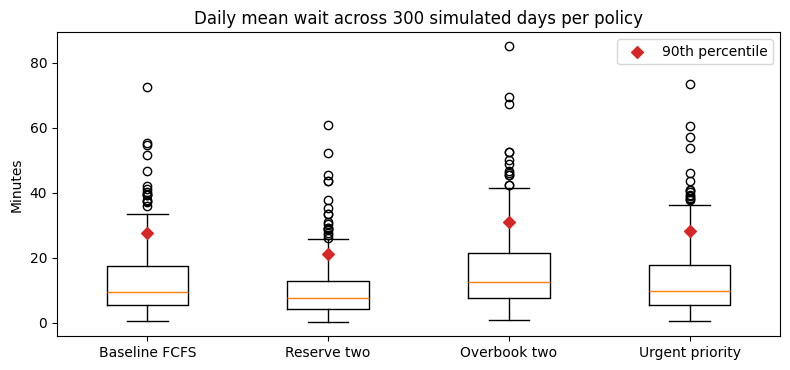

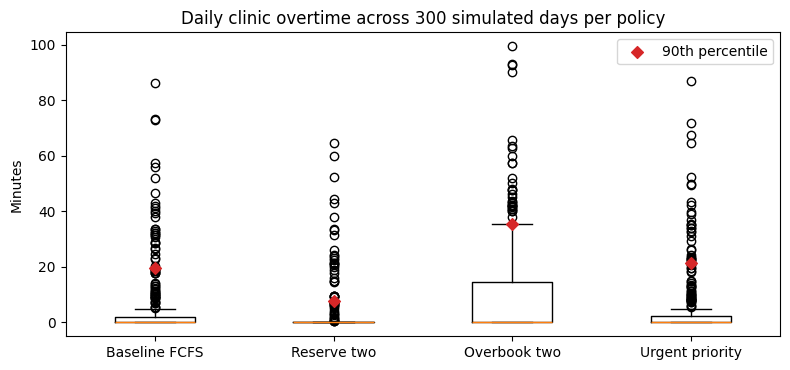

In [13]:
def summarise_policies(results):
    g = results.groupby("policy")
    return pd.DataFrame({
        "median_visits": g["visits"].median(),
        "median_started_by_close": g["started_by_close"].median(),
        "median_mean_wait": g["mean_wait_min"].median(),
        "median_p90_wait": g["p90_wait_min"].median(),
        "p90_of_p90_wait": g["p90_wait_min"].quantile(0.90),
        "median_utilization": g["utilization_before_close"].median(),
        "p90_overtime": g["overtime_min"].quantile(0.90),
        "mean_urgent_breaches": g["urgent_wait_breaches"].mean(),
        "median_routine_p90_wait": g["routine_p90_wait_min"].median(),
    }).round(2)


policy_summary = summarise_policies(policy_results)
display(policy_summary)

plot_labels = {
    "baseline_fcfs": "Baseline FCFS",
    "reserve_2_fcfs": "Reserve two",
    "overbook_2_score_guided": "Overbook two",
    "baseline_urgent_priority": "Urgent priority",
}
for metric, title in [("mean_wait_min", "Daily mean wait"),
                      ("overtime_min", "Daily clinic overtime")]:
    fig, ax = plt.subplots(figsize=(8, 3.8))
    samples = [policy_results.loc[policy_results["policy"].eq(policy), metric]
               for policy in plot_labels]
    ax.boxplot(samples)
    ax.scatter(range(1, len(samples) + 1), [values.quantile(0.90) for values in samples],
               marker="D", color="tab:red", zorder=3, label="90th percentile")
    ax.set_xticks(range(1, len(samples) + 1), labels=list(plot_labels.values()))
    ax.set(title=f"{title} across {len(simulation_seeds)} simulated days per policy", ylabel="Minutes")
    ax.legend()
    fig.tight_layout()
    plt.show()

The boxes show the middle half of simulated days, with the median marked inside each box. Red diamonds mark the 90th percentile. A single average can conceal a minority of days with long waits or overtime. The 90th percentile of daily 90th-percentile wait describes within-day tail waits on difficult days.

### Interpretation prompts

1. Which policy completes or starts the most visits before closing?
2. Which policy has the lowest tail waiting and overtime?
3. Does urgent priority improve urgent-delay outcomes? What happens to routine waiting?
4. Does any policy dominate every other policy, or are there trade-offs?
5. Which measures would you treat as constraints rather than components of a weighted score?

**Results.** Score-guided overbooking starts the most visits before closing, with a median of 32 compared with 30 for baseline FCFS, but raises 90th-percentile overtime from 19.76 to 35.65 minutes. Reserve two has the lowest high-day tail wait (47.23 minutes) and lowest 90th-percentile overtime (7.86 minutes), with a median of 28 starts before close. Urgent priority preserves the baseline median of 30 starts and cuts mean urgent breaches from 0.81 to 0.04 per day. Its median daily routine 90th-percentile wait increases from 24.83 to 26.84 minutes. These trade-offs rule out a single policy dominating all outcomes. I would review urgent breaches and overtime against explicit limits and set a minimum acceptable level of access before ranking policies.

## Exercise 5: Stress-test assumptions — 15 minutes

Policies should not be selected using only one assumed future. Repeat the policy comparison under:

1. **Demand surge:** set `urgent_rate=7.0`.
2. **Attendance drift:** set `no_show_logit_shift=-0.6`. This makes actual non-attendance less likely than the unchanged predictions suggest.

Store the two summaries as `surge_summary` and `attendance_drift_summary`. Identify any policy whose apparent advantage disappears or whose safety/workload outcomes worsen materially.

Explain why this is a policy stress test rather than external clinical validation.

In [14]:
surge_results = run_all_policies(urgent_rate=7.0)
surge_summary = summarise_policies(surge_results)

attendance_drift_results = run_all_policies(no_show_logit_shift=-0.6)
attendance_drift_summary = summarise_policies(attendance_drift_results)

print("\nDemand surge (urgent_rate = 7):")
display(surge_summary)
print("Attendance drift (logit shift = -0.6):")
display(attendance_drift_summary)

# Compare the key outcomes across the three scenarios
key = ["median_mean_wait", "p90_of_p90_wait", "p90_overtime", "mean_urgent_breaches"]
display(pd.concat({"normal": policy_summary[key], "surge": surge_summary[key],
                   "drift": attendance_drift_summary[key]}, axis=1))


Demand surge (urgent_rate = 7):


,median_visits,median_started_by_close,median_mean_wait,median_p90_wait,p90_of_p90_wait,median_utilization,p90_overtime,mean_urgent_breaches,median_routine_p90_wait
policy,,,,,,,,,
baseline_fcfs,33.0,32.0,20.00,42.58,89.15,0.90,67.77,2.68,42.92
baseline_urgent_priority,33.0,32.0,20.12,49.41,108.25,0.90,65.30,0.23,52.11
overbook_2_score_guided,35.0,34.0,24.86,50.28,99.64,0.93,85.82,3.18,49.34
reserve_2_fcfs,31.0,31.0,14.77,35.76,76.11,0.86,44.48,2.14,35.31


Attendance drift (logit shift = -0.6):


,median_visits,median_started_by_close,median_mean_wait,median_p90_wait,p90_of_p90_wait,median_utilization,p90_overtime,mean_urgent_breaches,median_routine_p90_wait
policy,,,,,,,,,
baseline_fcfs,32.0,32.0,11.13,27.34,60.71,0.86,29.84,0.93,26.95
baseline_urgent_priority,32.0,32.0,11.34,29.42,68.67,0.86,30.62,0.04,30.44
overbook_2_score_guided,34.0,33.0,15.28,33.98,68.44,0.90,48.08,1.23,32.78
reserve_2_fcfs,30.0,30.0,8.46,23.25,50.68,0.81,14.80,0.66,23.33


normal                                                              surge  \
                         median_mean_wait p90_of_p90_wait p90_overtime mean_urgent_breaches median_mean_wait   
policy                                                                                                         
baseline_fcfs                        9.37           54.73        19.76                 0.81            20.00   
baseline_urgent_priority             9.61           59.07        21.33                 0.04            20.12   
overbook_2_score_guided             12.42           60.18        35.65                 1.00            24.86   
reserve_2_fcfs                       7.54           47.23         7.86                 0.56            14.77   

                                                                                      drift                  \
                         p90_of_p90_wait p90_overtime mean_urgent_breaches median_mean_wait p90_of_p90_wait   
policy                                                                                                        
baseline_fcfs                      89.15        67.77                 2.68            11.13           60.71   
baseline_urgent_priority          108.25        65.30                 0.23            11.34           68.67   
overbook_2_score_guided            99.64        85.82                 3.18            15.28           68.44   
reserve_2_fcfs                     76.11        44.48                 2.14             8.46           50.68   

                                                            
                         p90_overtime mean_urgent_breaches  
policy                                                      
baseline_fcfs                   29.84                 0.93  
baseline_urgent_priority        30.62                 0.04  
overbook_2_score_guided         48.08                 1.23  
reserve_2_fcfs                  14.80                 0.66

The demand scenario raises mean daily urgent arrivals from four to seven. The attendance scenario multiplies actual no-show odds by exp(-0.6), about 0.55, while holding predicted scores and booking rules fixed. Both scenarios reuse the same synthetic model. External validation would require independent observations of demand, attendance, service times and queue outcomes. The surge increases every policy's tail wait and 90th-percentile overtime. Urgent priority holds mean breaches to 0.23 per day versus 2.68 under baseline FCFS, while its high-day tail wait rises from 59.07 to 108.25 minutes. Under attendance drift, overbooking's median access gain shrinks from two additional starts to one. Its 90th-percentile overtime rises from 35.65 to 48.08 minutes and its mean urgent breaches rise from 1.00 to 1.23 per day.

## Exercise 6: Audit subgroup effects — 15 minutes

The score partly reflects travel time, so score-guided overbooking may affect the two synthetic access groups differently.

For the score-guided policy:

1. Count standard and overbooked requests by `access_group`.
2. Across at least 200 simulated days, calculate attended sample size, mean wait, and 90th-percentile wait by group.
3. Compare those results with the baseline.
4. Report sample sizes beside every subgroup measure.
5. Explain why an observed difference is a reason to investigate, not proof of discrimination or harm.

Do not treat missing `access_group` for synthetic urgent arrivals as one of the scheduled-patient groups.

In [15]:
sg_schedule = policy_definitions["overbook_2_score_guided"]["schedule"]
booking_audit_by_group = pd.crosstab(sg_schedule["access_group"], sg_schedule["booking_type"], margins=True)

# Patients whose slot receives the extra booking (highest predicted no-show)
print("Host patients of the overbooked slots:")
display(baseline_schedule.nlargest(2, "predicted_no_show_probability")[
    ["request_id", "access_group", "travel_minutes", "scheduled_minute", "predicted_no_show_probability"]])


def subgroup_waits(policy):
    spec = policy_definitions[policy]
    days = [simulate_clinic_day(spec["schedule"], seed=int(s), queue_rule=spec["queue_rule"])
            for s in simulation_seeds]
    v = pd.concat(days)
    v = v[v["source"] == "scheduled"]  # drop urgent arrivals (no access_group)
    out = v.groupby("access_group")["wait_min"].agg(
        attended_n="count", mean_wait="mean", p90_wait=lambda w: w.quantile(0.90))
    return out.assign(policy=policy)


subgroup_results = pd.concat(
    [subgroup_waits(p) for p in ["baseline_fcfs", "overbook_2_score_guided"]]
).reset_index().round(2)

display(booking_audit_by_group)
display(subgroup_results)
baseline_subgroups = subgroup_results.query("policy == 'baseline_fcfs'").set_index("access_group")
overbook_subgroups = subgroup_results.query("policy == 'overbook_2_score_guided'").set_index("access_group")
subgroup_comparison = baseline_subgroups.drop(columns="policy").add_prefix("baseline_").join(
    overbook_subgroups.drop(columns="policy").add_prefix("overbook_")
)
for metric in ["mean_wait", "p90_wait"]:
    subgroup_comparison[f"change_{metric}"] = (
        subgroup_comparison[f"overbook_{metric}"] - subgroup_comparison[f"baseline_{metric}"]
    ).round(2)
display(subgroup_comparison)

Host patients of the overbooked slots:


,request_id,access_group,travel_minutes,scheduled_minute,predicted_no_show_probability
5,R005,far_from_clinic,72,60,0.31995
27,R027,far_from_clinic,72,390,0.31995


booking_type,overbooked,standard,All
access_group,,,
far_from_clinic,0,9,9
near_clinic,2,21,23
All,2,30,32


,access_group,attended_n,mean_wait,p90_wait,policy
0,far_from_clinic,2149,11.15,34.75,baseline_fcfs
1,near_clinic,5710,13.77,39.66,baseline_fcfs
2,far_from_clinic,2149,14.14,40.40,overbook_2_score_guided
3,near_clinic,6253,16.93,45.49,overbook_2_score_guided


,baseline_attended_n,baseline_mean_wait,baseline_p90_wait,overbook_attended_n,overbook_mean_wait,overbook_p90_wait,change_mean_wait,change_p90_wait
access_group,,,,,,,,
far_from_clinic,2149,11.15,34.75,2149,14.14,40.40,2.99,5.65
near_clinic,5710,13.77,39.66,6253,16.93,45.49,3.16,5.83


The two additional bookings go to near-clinic patients, while both existing bookings that host them belong to far-from-clinic patients. The wait table excludes urgent arrivals. Sample sizes count attended episodes across 300 days, with the same fictional patients appearing repeatedly. Group averages can reflect slot positions, attendance and congestion. A gap warrants investigation of these mechanisms and patient experience before drawing conclusions about discrimination or harm. For far-clinic patients, overbooking raises mean wait by 2.99 minutes and the 90th percentile by 5.65 minutes (2,149 episodes under each policy). For near-clinic patients, mean wait increases by 3.16 minutes and the 90th percentile by 5.83 minutes (5,710 baseline and 6,253 overbooking episodes). The near-clinic comparison also includes episodes from the two added requests.

## Exercise 7: Recommendation memo — 10 minutes

Write 150–250 words addressed to the fictional clinic manager. Include:

1. the policy you recommend for a limited pilot—or why none should be piloted;
2. evidence from access, tail waiting, overtime, and urgent-delay outcomes;
3. what happened under demand and attendance stress tests;
4. any subgroup concern and its sample size;
5. an override or escalation mechanism;
6. three measures to monitor; and
7. one important limitation of the synthetic model.

Do not describe the selected policy as clinically validated or ready for autonomous deployment.

### Recommendation memo

To the clinic manager,

I recommend a limited, clinician-supervised pilot of non-preemptive urgent priority with the existing 30-slot template. Across 300 simulated days, median starts before closing stayed at 30, and urgent waits over 30 minutes fell from 0.81 to 0.04 per day. The high-day tail wait rose from 54.73 to 59.07 minutes, and 90th-percentile overtime rose from 19.76 to 21.33 minutes.

During the demand surge, urgent priority averaged 0.23 breaches per day, while 90th-percentile overtime reached 65.30 minutes. Under attendance drift, it retained 32 median starts before close and averaged 0.04 breaches, with 30.62 minutes of 90th-percentile overtime. I would defer score-guided overbooking. Both slots receiving extra bookings belonged to far-clinic patients, whose mean wait rose from 11.15 to 14.14 minutes across 2,149 attended episodes per policy.

The shift lead should be able to override queue order after reassessment and escalate capacity when queues build. Monitor the urgent threshold breach rate, the 90th-percentile routine wait by access group with episode counts, and 90th-percentile overtime. Review these against agreed stop criteria before expanding the pilot. The simulation assumes two continuously available clinicians and uses synthetic attendance and service times. Local queue data should inform any decision to proceed.

## Reflection questions

1. Why can average daily workload be below nominal capacity while patients still wait?
2. What information was available at scheduling time, and what was realized later?
3. Why might optimizing only utilization produce an undesirable policy?
4. How does non-preemptive urgent priority differ from interrupting a consultation?
5. What operational features are absent from this simulation—rooms, breaks, staff roles, or something else—and which omission matters most?
6. How would deployment change the future data used to retrain a no-show model?
7. What evidence would be required before applying this approach in a real clinic?

## Optional extensions

- Add a lunch break or temporary clinician absence.
- Add a room constraint separate from clinician availability.
- Compare three-clinician staffing with two-clinician overtime.
- Calculate confidence intervals across simulated days.
- Replace the supplied score with a leakage-safe model trained on synthetic historical days.
- Formulate a small constrained grid search that rejects policies exceeding an urgent-delay or overtime limit.

## Reproducibility note

The notebook creates all data in memory and writes no files. Rerunning from a fresh kernel reproduces the fixture and simulation seeds. Changing the generator or policy assumptions changes the teaching results; record any such changes in your submission.

### Reflection answers

1. Patients arrive in clusters and consultations vary in length. Both clinicians can be busy at once even when later periods are idle, so average spare capacity can coexist with a queue.
2. Request order, travel history, prior misses, predicted non-attendance and the appointment template are known before opening. Attendance, late or early arrival, consultation duration and urgent demand are realized later.
3. Filling most staffed minutes leaves little slack for urgent arrivals or long consultations, which can raise tail waits and overtime even as utilization improves.
4. Non-preemptive priority selects an urgent patient from the waiting queue when a clinician becomes free. A consultation already in progress continues to completion.
5. The model omits breaks, room availability, triage staff and administrative work. Breaks and other clinician duties matter here because they reduce the available clinician minutes and can concentrate congestion at predictable times.
6. Booking rules change who gets an appointment, which time they receive and whose attendance is observed. If longer waits or crowding affect future attendance, retraining data can also reflect the earlier policy's effects. Track policy exposure and unbooked requests to interpret the resulting data.
7. A clinic would need representative local demand, arrival and consultation data, separate validation of attendance calibration and queue predictions, and a supervised comparison of access, delays, staff workload and subgroup outcomes with predefined review and stop rules.